# 02 Parameter Ensemble：6336 组参数投票形成 ETF 权重（PyCharm 静态检查友好版）

这个 notebook **完全独立于原来的 00–08 文件**，不会修改原策略、原回测结果或原 pipeline。

思路：
1. 对 7 个参数取多个合理值；
2. 只保留 `extreme > fear` 的组合，共 6336 组；
3. 每个交易日，每组参数沿用原 `signals()` 的决策树逻辑，选出 1 只 ETF；
4. 某 ETF 当天的权重 = 选择它的参数组数 / 6336；
5. 用 `T 日收盘生成权重 → T+1 开盘调仓` 做独立组合回测；
6. 与 SPY / TQQQ Buy & Hold、原单参数 baseline 做比较。

> 注意：这里研究的是“7 参数 ensemble / 投票加权”本身，所以不叠加原来的止损止盈网格。


> 本版本（原文件名 `09_parameter_ensemble_2.ipynb`）只修改本文件自身的导入/绑定方式，不会改动 `00_engine.ipynb`、`07_run_pipeline.ipynb` 或任何其他 pipeline 文件。


In [1]:
from pathlib import Path
import os
import json
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_pipeline_dir():
    """支持从项目根目录、pipeline 目录及项目内子目录启动。"""
    roots = (
        [Path(os.environ["ETF_PROJECT_ROOT"]).expanduser()]
        if os.environ.get("ETF_PROJECT_ROOT")
        else []
    )
    roots += [Path.cwd(), *Path.cwd().parents]

    for root in roots:
        for candidate in (root / "pipeline", root):
            if (candidate / "00_engine.ipynb").is_file():
                return candidate.resolve()

    raise FileNotFoundError(
        "找不到 pipeline 文件夹。请把工作目录设为项目根目录或 pipeline 目录。"
    )


PIPELINE_DIR = find_pipeline_dir()


def load_notebook_definitions(filename):
    """读取 notebook 中的定义；不执行带 pipeline-entry tag 的入口单元格。"""
    path = next(iter(sorted(PIPELINE_DIR.rglob(filename))), PIPELINE_DIR / filename)   # 在 pipeline 各子文件夹中查找
    notebook = json.loads(path.read_text(encoding="utf-8"))
    namespace = {"__name__": "pipeline_module"}

    for number, item in enumerate(notebook["cells"]):
        if item["cell_type"] != "code":
            continue
        if "pipeline-entry" in item.get("metadata", {}).get("tags", []):
            continue

        exec(
            compile("".join(item["source"]), f"{path}:cell{number}", "exec"),
            namespace,
        )

    return namespace


# ------------------------------------------------------------
# 显式绑定 00_engine.ipynb 中本文件会使用的对象。
# 不再使用 globals()[name] 动态注入，这样 PyCharm 能识别这些名字，
# 从而消除 IS_START / TICKS / prep / backtest 等 unresolved reference 红线。
# ------------------------------------------------------------
_engine = load_notebook_definitions("00_engine.ipynb")

IS_START = _engine["IS_START"]
IS_END = _engine["IS_END"]
OOS_START = _engine["OOS_START"]
OOS_END = _engine["OOS_END"]
TICKS = _engine["TICKS"]
ONE_WAY_BPS = _engine["ONE_WAY_BPS"]

wilder_rsi = _engine["wilder_rsi"]
prep = _engine["prep"]
signals = _engine["signals"]
backtest = _engine["backtest"]
metrics = _engine["metrics"]
fmt = _engine["fmt"]


## 1. 参数网格

映射到原决策树：
- RSI 周期 → `rsi_n`
- SPY 均线 → `spy_sma`
- 过热线 → 同时替代原 `qqq_rsi_bull` 与 `spy_rsi_bull`
- 超卖线 → 同时替代原 `tqqq_rsi_dip` 与固定的 `SPY RSI < 30`
- UVXY 恐慌线 → `uvxy_hi`
- 极端线 → `uvxy_ext`
- SQQQ 线 → 同时替代原 `sqqq_exit` 与固定的 `SQQQ RSI < 31`

原来的 QQQ 20 日均线和 TQQQ 20 日均线保持不变。


In [2]:
PARAM_GRID = {
    'rsi_n':[7,10,14],
    'spy_sma':[100,120,150,200],
    'overheat':[70,75,80,85],
    'oversold':[20,25,30,35],
    'uvxy_fear':[64,70,74,80],
    'uvxy_extreme':[80,84,88],
    'sqqq_line':[30,34,38],
}

def build_parameter_combinations():
    keys=list(PARAM_GRID)
    combos=[]
    for vals in itertools.product(*(PARAM_GRID[k] for k in keys)):
        p=dict(zip(keys,vals))
        if p['uvxy_extreme'] > p['uvxy_fear']:
            combos.append(p)
    assert len(combos)==6336, f'应为6336组，实际{len(combos)}'
    return combos

PARAM_COMBOS=build_parameter_combinations()
print('有效参数组合数:', len(PARAM_COMBOS))
display(pd.DataFrame(PARAM_COMBOS).head())


有效参数组合数: 6336


,rsi_n,spy_sma,overheat,oversold,uvxy_fear,uvxy_extreme,sqqq_line
0,7,100,70,20,64,80,30
1,7,100,70,20,64,80,34
2,7,100,70,20,64,80,38
3,7,100,70,20,64,84,30
4,7,100,70,20,64,84,34


## 2. 预计算 RSI / SMA

为了避免 6336 组参数重复计算指标，这里只计算一次 RSI(7/10/14)、SPY SMA(100/120/150/200)、QQQ SMA20 和 TQQQ SMA20。


In [3]:
def precompute_indicators(C):
    """全部转成 NumPy，避免 6336×数千日循环里反复做 pandas iloc。"""
    ticker_to_col={t:i for i,t in enumerate(TICKS)}
    rsi_cache={}
    for n in PARAM_GRID['rsi_n']:
        rsi_cache[n]=np.column_stack([
            wilder_rsi(C[t].values,n) for t in TICKS
        ])
    return {
        'ticker_to_col':ticker_to_col,
        'rsi':rsi_cache,
        'spy_sma':{n:C['SPY'].rolling(n).mean().to_numpy(float) for n in PARAM_GRID['spy_sma']},
        'qqq_sma20':C['QQQ'].rolling(20).mean().to_numpy(float),
        'tqqq_sma20':C['TQQQ'].rolling(20).mean().to_numpy(float),
        'prices':{t:C[t].to_numpy(float) for t in ['SPY','QQQ','TQQQ']},
    }


## 3. 单组参数每天选 1 只 ETF

这部分沿用 `00_engine.ipynb` 里的原始 `signals()` 决策树，只把这 7 个参数改成可变。


In [4]:
def targets_for_parameter_set(C, indicators, p):
    """一次性为整段历史生成某一组参数的 ETF target code；比逐日 pandas 判断快很多。"""
    col=indicators['ticker_to_col']
    r=indicators['rsi'][p['rsi_n']]
    s_spy=indicators['spy_sma'][p['spy_sma']]
    s_qqq=indicators['qqq_sma20']
    s_tqqq=indicators['tqqq_sma20']
    pspy=indicators['prices']['SPY']
    pqqq=indicators['prices']['QQQ']
    ptq=indicators['prices']['TQQQ']

    n=len(C)
    target=np.full(n,-1,dtype=np.int16)
    valid=(~np.isnan(r).any(axis=1) & ~np.isnan(s_spy) & ~np.isnan(s_qqq) & ~np.isnan(s_tqqq))

    # Bull branch
    bull=valid & (pspy>s_spy)
    hot=bull & ((r[:,col['QQQ']]>p['overheat']) | (r[:,col['SPY']]>p['overheat']))
    target[bull]=col['TQQQ']
    target[hot]=col['UVXY']

    # Bear branch，严格保留原 if/elif 顺序
    rem=valid & ~bull

    m=rem & (r[:,col['TQQQ']] < p['oversold'])
    target[m]=col['TECL']; rem &= ~m

    m=rem & (r[:,col['SPY']] < p['oversold'])
    target[m]=col['SPXL']; rem &= ~m

    fear=rem & (r[:,col['UVXY']] > p['uvxy_fear'])
    extreme=fear & (r[:,col['UVXY']] > p['uvxy_extreme'])
    non_extreme=fear & ~extreme
    target[non_extreme]=col['UVXY']

    ext_q_up=extreme & (pqqq>s_qqq)
    target[ext_q_up & (r[:,col['SQQQ']] < p['sqqq_line'])]=col['TECS']
    target[ext_q_up & ~(r[:,col['SQQQ']] < p['sqqq_line'])]=col['TECL']

    ext_q_down=extreme & ~(pqqq>s_qqq)
    target[ext_q_down & (r[:,col['TECS']] >= r[:,col['BSV']])]=col['TECS']
    target[ext_q_down & (r[:,col['TECS']] < r[:,col['BSV']])]=col['BSV']

    # 非恐慌分支
    normal=rem & ~fear
    tq_up=normal & (ptq>s_tqqq)
    target[tq_up & (r[:,col['SQQQ']] < p['sqqq_line'])]=col['TECS']
    target[tq_up & ~(r[:,col['SQQQ']] < p['sqqq_line'])]=col['TECL']

    tq_down=normal & ~(ptq>s_tqqq)
    target[tq_down & (r[:,col['TECS']] >= r[:,col['BSV']])]=col['TECS']
    target[tq_down & (r[:,col['TECS']] < r[:,col['BSV']])]=col['BSV']

    return target,valid


## 4. 6336 组投票 → 每日 ETF 权重

正式样本从 `IS_START` 开始；由于最长均线是 200 日，正式样本期内要求每天都必须有完整的 6336 组投票。


In [5]:
def generate_ensemble_weights(C, combos=None, start=None, verbose=True):
    combos=PARAM_COMBOS if combos is None else combos
    indicators=precompute_indicators(C)
    n=len(C); m=len(TICKS)
    votes_np=np.zeros((n,m),dtype=np.int32)
    valid_n_np=np.zeros(n,dtype=np.int32)
    start_ts=pd.Timestamp(start) if start is not None else None
    start_pos=0 if start_ts is None else C.index.searchsorted(start_ts)
    rows=np.arange(n)

    for j,p in enumerate(combos,1):
        target,valid=targets_for_parameter_set(C,indicators,p)
        if start_pos>0:
            valid[:start_pos]=False
        idx=rows[valid]
        np.add.at(votes_np,(idx,target[valid]),1)
        valid_n_np[valid]+=1
        if verbose and (j%1000==0 or j==len(combos)):
            print(f'已完成 {j}/{len(combos)} 组参数')

    votes=pd.DataFrame(votes_np,index=C.index,columns=TICKS)
    valid_n=pd.Series(valid_n_np,index=C.index,name='valid_parameter_count')
    weights=votes.div(valid_n.replace(0,np.nan),axis=0)

    formal=valid_n.loc[pd.Timestamp(start or IS_START):]
    formal=formal[formal>0]
    if len(formal) and (formal!=len(combos)).any():
        bad=formal[formal!=len(combos)]
        raise ValueError(f'正式回测期发现未满6336组的日期，例如：{bad.head().to_dict()}')

    # 基本一致性检查
    chk=weights.loc[formal.index].sum(axis=1)
    if len(chk) and not np.allclose(chk.values,1.0,atol=1e-10):
        raise AssertionError('部分日期 ETF 权重之和不等于 1。')

    return weights,votes,valid_n


## 5. 多 ETF 权重回测

原 `backtest()` 只能同时持有 1 只 ETF，因此这里单独写一个组合回测器，不会改动原函数。

规则：T 日收盘得到权重，T+1 开盘调仓；普通 ETF 每边 5bps，UVXY 每边 10bps。


In [6]:
def backtest_weighted_portfolio(O,C,weights,start=IS_START):
    idx=C.index; tickers=list(TICKS)
    qty=np.zeros(len(tickers),dtype=float)
    eq=pd.Series(np.nan,index=idx,dtype=float)
    turnover=pd.Series(np.nan,index=idx,dtype=float)
    cost_paid=pd.Series(0.0,index=idx,dtype=float)
    nav=1.0; pending=None; started=False

    for d in idx:
        if d < pd.Timestamp(start):
            continue
        open_px=O.loc[d,tickers].to_numpy(float)
        close_px=C.loc[d,tickers].to_numpy(float)

        if not started:
            started=True
            eq.loc[d]=nav
        else:
            current_value=float(np.dot(qty,open_px)) if qty.sum()!=0 else nav
            if pending is not None:
                new_w=pending.reindex(tickers).fillna(0.0).to_numpy(float)
                if qty.sum()==0:
                    old_w=np.zeros(len(tickers))
                else:
                    av=qty*open_px
                    old_w=av/av.sum()
                delta=new_w-old_w
                rates=np.array([ONE_WAY_BPS[t]/1e4 for t in tickers])
                tc=current_value*float(np.sum(np.abs(delta)*rates))
                investable=max(current_value-tc,0.0)
                qty=np.divide(investable*new_w,open_px,out=np.zeros_like(new_w),where=open_px>0)
                turnover.loc[d]=float(np.sum(np.abs(delta)))
                cost_paid.loc[d]=tc
            nav=float(np.dot(qty,close_px))
            eq.loc[d]=nav

        row=weights.loc[d]
        if row.notna().any():
            pending=row.fillna(0.0)

    eq=eq.dropna()
    diagnostics=pd.DataFrame({'turnover':turnover,'cost_paid':cost_paid}).loc[eq.index]
    return eq,diagnostics


## 6. 与原 baseline / SPY / TQQQ 对比


In [7]:
def buy_and_hold_equity(C,ticker,start=IS_START):
    s=C[ticker].loc[start:].dropna()
    return s/s.iloc[0]

def evaluate_results(C,ensemble_eq,original_eq):
    rows=[]
    series_map={
        'Ensemble 6336':ensemble_eq,
        'Original baseline':original_eq,
        'SPY Buy&Hold':buy_and_hold_equity(C,'SPY'),
        'TQQQ Buy&Hold':buy_and_hold_equity(C,'TQQQ'),
    }
    for name,eq in series_map.items():
        for label,a,b in [('IS',IS_START,IS_END),('OOS',OOS_START,OOS_END),('OOS ex-2020','2021-01-01',OOS_END)]:
            if len(eq.loc[a:b])<2:
                continue
            rows.append({'Strategy':name,'Period':label,**fmt(metrics(eq,a=a,b=b))})
    table=pd.DataFrame(rows)
    display(table)
    return table

def plot_results(weights,ensemble_eq,original_eq,C):
    fig1,ax1=plt.subplots(figsize=(11,5))
    weights.loc[IS_START:].plot.area(ax=ax1,stacked=True)
    ax1.set_title('Parameter Ensemble ETF Weights')
    ax1.set_ylabel('Portfolio weight'); ax1.set_ylim(0,1)
    ax1.legend(loc='upper left',bbox_to_anchor=(1.01,1))
    plt.tight_layout(); plt.show()

    fig2,ax2=plt.subplots(figsize=(11,5))
    (ensemble_eq/ensemble_eq.iloc[0]).plot(ax=ax2,label='Ensemble 6336')
    (original_eq/original_eq.iloc[0]).plot(ax=ax2,label='Original baseline')
    buy_and_hold_equity(C,'SPY',ensemble_eq.index[0]).plot(ax=ax2,label='SPY Buy&Hold')
    buy_and_hold_equity(C,'TQQQ',ensemble_eq.index[0]).plot(ax=ax2,label='TQQQ Buy&Hold')
    ax2.axvline(pd.Timestamp(OOS_START),color='gray',ls='--')
    ax2.set_yscale('log'); ax2.set_title('Equity Curves (log scale)'); ax2.legend()
    plt.tight_layout(); plt.show()
    return fig1,fig2


## 7. 一键入口

这个 notebook **不会加入原来的 `07_run_pipeline.ipynb`**，所以不会影响你们原结果。单独打开本文件，点击 Run All 即可。


In [8]:
def main(csv_path=None,start=IS_START,verbose=True):
    O,H,L,C=prep(csv_path)
    print('数据区间:',C.index[0].date(),'~',C.index[-1].date())
    print('参数组合数:',len(PARAM_COMBOS))

    weights,votes,valid_n=generate_ensemble_weights(C,PARAM_COMBOS,start,verbose)
    ensemble_eq,diag=backtest_weighted_portfolio(O,C,weights,start=start)

    original_tg=signals(C)
    original_eq,original_trades=backtest(O,H,L,C,original_tg,None,None,True,start=start)

    table=evaluate_results(C,ensemble_eq,original_eq)
    latest_date=weights.dropna(how='all').index[-1]
    latest=pd.DataFrame({
        'votes':votes.loc[latest_date],
        'weight':weights.loc[latest_date],
        'weight_%':weights.loc[latest_date]*100,
    }).sort_values('weight',ascending=False)
    print('\n最新投票日期:',latest_date.date())
    display(latest.round({'weight':4,'weight_%':2}))
    figs=plot_results(weights,ensemble_eq,original_eq,C)
     # ---- 保存到 results/ ----
    root=PIPELINE_DIR.parent if PIPELINE_DIR.name=='pipeline' else PIPELINE_DIR
    tdir,fdir,sdir=root/'results'/'tables',root/'results'/'figures',root/'results'/'signals'
    for d in (tdir,fdir,sdir): d.mkdir(parents=True,exist_ok=True)
    table.to_csv(tdir/'ensemble_metrics.csv',index=False,encoding='utf-8-sig')
    diag.to_csv(tdir/'ensemble_turnover_cost.csv',encoding='utf-8-sig')
    weights.dropna(how='all').to_csv(sdir/'ensemble_weights_history.csv',encoding='utf-8-sig')
    latest.to_csv(sdir/'ensemble_latest_allocation.csv',encoding='utf-8-sig')
    figs[0].savefig(fdir/'ensemble_weights.png',dpi=150,bbox_inches='tight')
    figs[1].savefig(fdir/'ensemble_equity.png',dpi=150,bbox_inches='tight')
    print('已保存到',root/'results')
    print('\nParameter ensemble 运行完成。')

    return {
        'parameter_combinations':PARAM_COMBOS,
        'weights':weights,
        'votes':votes,
        'valid_parameter_count':valid_n,
        'ensemble_equity':ensemble_eq,
        'ensemble_diagnostics':diag,
        'original_baseline_equity':original_eq,
        'metrics':table,
        'latest_date':latest_date,
        'latest_allocation':latest,
        'figures':figs,
    }


数据区间: 2011-10-03 ~ 2026-10-13
参数组合数: 6336
已完成 1000/6336 组参数
已完成 2000/6336 组参数
已完成 3000/6336 组参数
已完成 4000/6336 组参数
已完成 5000/6336 组参数
已完成 6000/6336 组参数
已完成 6336/6336 组参数


,Strategy,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
0,Ensemble 6336,IS,0.516,0.439,1.168,1.800,-0.601,0.858
1,Ensemble 6336,OOS,1.155,0.594,1.589,2.567,-0.491,2.355
2,Ensemble 6336,OOS ex-2020,0.597,0.543,1.133,1.741,-0.491,1.216
3,Original baseline,IS,0.412,0.497,0.940,1.412,-0.758,0.543
4,Original baseline,OOS,1.445,0.731,1.585,2.548,-0.512,2.821
5,Original baseline,OOS ex-2020,0.834,0.657,1.249,1.946,-0.512,1.629
6,SPY Buy&Hold,IS,0.144,0.128,1.124,1.586,-0.193,0.746
7,SPY Buy&Hold,OOS,0.151,0.200,0.804,1.140,-0.337,0.448
8,SPY Buy&Hold,OOS ex-2020,0.150,0.166,0.927,1.351,-0.245,0.614
9,TQQQ Buy&Hold,IS,0.503,0.474,1.101,1.554,-0.581,0.867



最新投票日期: 2026-10-13


,votes,weight,weight_%
TQQQ,6336,1.0,100.0
SPY,0,0.0,0.0
QQQ,0,0.0,0.0
UVXY,0,0.0,0.0
TECL,0,0.0,0.0
SPXL,0,0.0,0.0
SQQQ,0,0.0,0.0
TECS,0,0.0,0.0
BSV,0,0.0,0.0


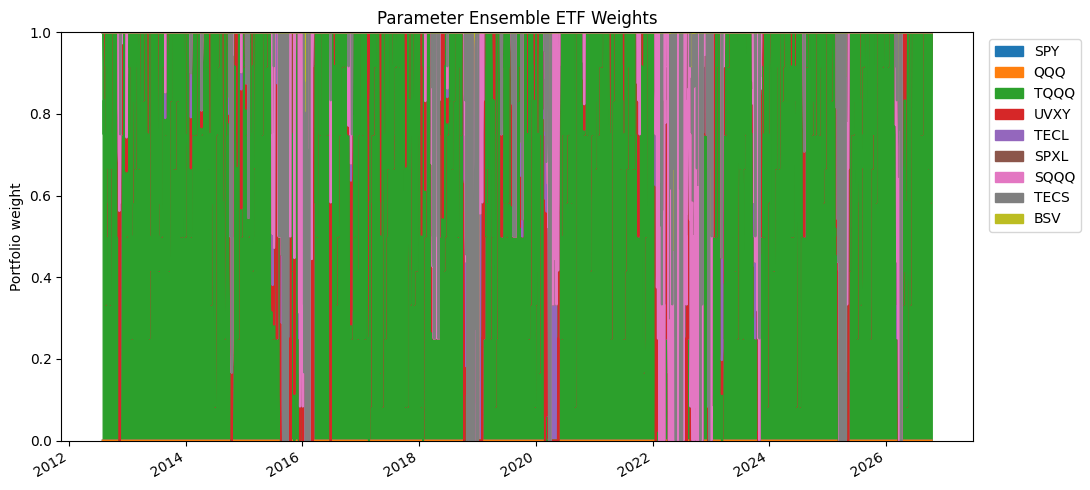

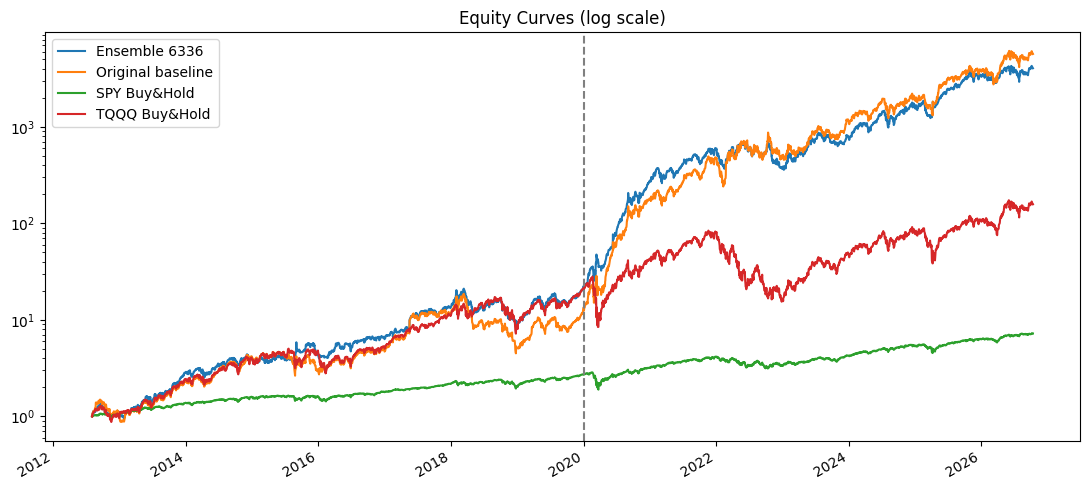

已保存到 E:\subjects\研一\Financial Econometrics\Project\Volumn-Rotation\results

Parameter ensemble 运行完成。


In [9]:
# ===== 只需修改这里，然后 Run All =====
CSV_PATH=None
START=IS_START
VERBOSE=True

results_ensemble=main(
    csv_path=CSV_PATH,
    start=START,
    verbose=VERBOSE,
)
